# 📈 Pelican-VLA 0.5: Trajectory, Latency & Tracking Diagnostics
### Session: `20261015T162257+0700_797af814`
**Task:** `serving brewed coffee` (Astribot S1)

Notebook này phân tích toàn diện 97 chu kỳ suy luận:
1. **Inference Latency Timeline:** Phân tích thời gian suy luận từng cycle so với các mốc an toàn.
2. **Sensor Freshness (Input Ages):** Độ tươi của ảnh camera và trạng thái khớp đo được.
3. **Quỹ đạo điều khiển 16 khớp:** So sánh `raw_action` (model) vs `limited_command` (bảo vệ) vs `measured_state` (thực tế).
4. **Phân tích cú giật tại Cycle 15:** Điều tra nguyên nhân gây ra `raw_arm_jump=0.145rad` và tracking warning.
5. **Hành vi hai kẹp (Grippers):** Trạng thái đóng/mở của kẹp trái và kẹp phải.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = Path('/home/anhnb9/Documents/Pelican-VLA05')
SESSION_DIR = REPO_ROOT / 'logs/sessions/20261015T162257+0700_797af814'

# Tên 16 khớp theo quy ước Astribot S1 VLA
JOINT_NAMES = [
    'L_Arm_J0', 'L_Arm_J1', 'L_Arm_J2', 'L_Arm_J3', 'L_Arm_J4', 'L_Arm_J5', 'L_Arm_J6',
    'R_Arm_J0', 'R_Arm_J1', 'R_Arm_J2', 'R_Arm_J3', 'R_Arm_J4', 'R_Arm_J5', 'R_Arm_J6',
    'L_Gripper', 'R_Gripper'
]

## 1. Đọc và phân tích Latency toàn bộ 97 Cycles

Tìm thấy 97 files cycle JSON.


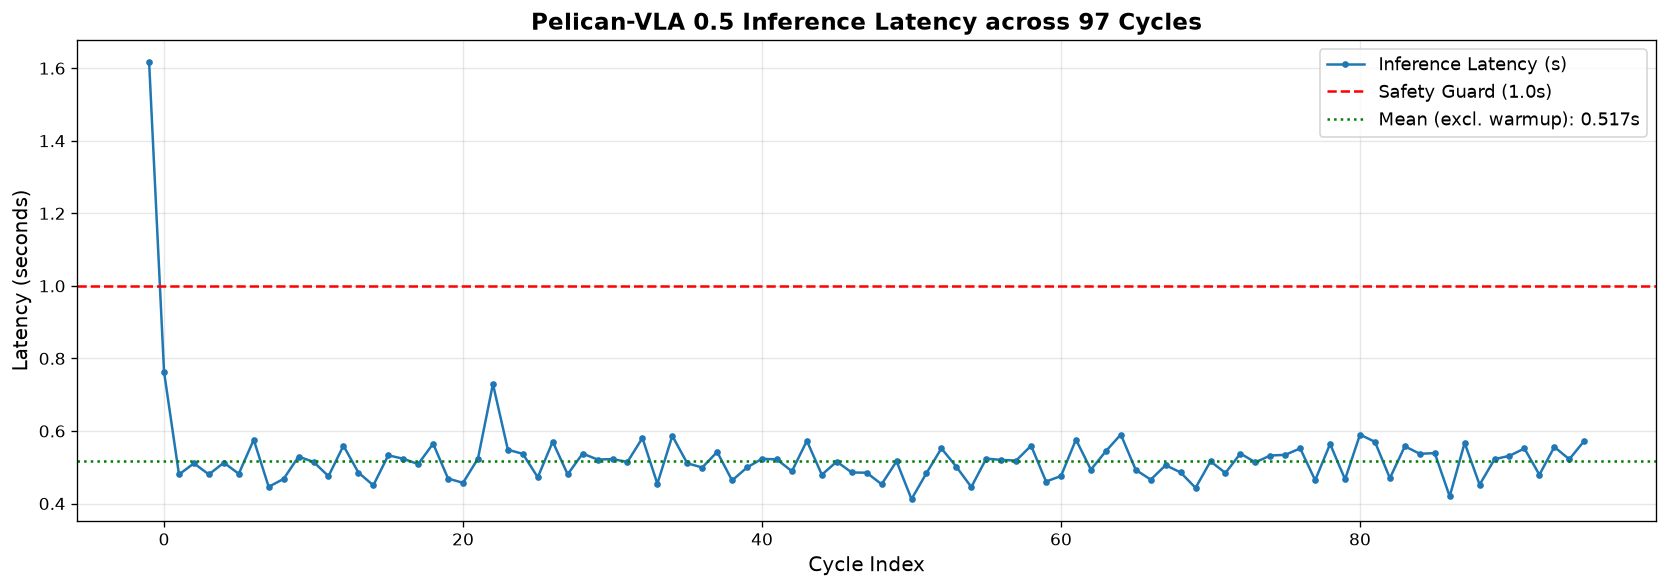

Latency tóm tắt:
 - Warm-up (cycle -1): 1.618s
 - Min latency: 0.412s
 - Max latency (realtime): 0.763s
 - Mean latency: 0.517s
 - Median latency: 0.516s


In [2]:
cycle_files = sorted(SESSION_DIR.glob('cycles/cycle_*.json'))
print(f"Tìm thấy {len(cycle_files)} files cycle JSON.")

cycles_data = []
for f in cycle_files:
    data = json.loads(f.read_text())
    cycles_data.append(data)

# Sắp xếp theo thứ tự cycle
cycles_data.sort(key=lambda x: x['cycle'])

cycles = [d['cycle'] for d in cycles_data]
latencies = [d.get('latency', 0) for d in cycles_data]

plt.figure(figsize=(14, 5), dpi=120)
plt.plot(cycles, latencies, marker='o', markersize=3, color='#1f77b4', linewidth=1.5, label='Inference Latency (s)')
plt.axhline(1.0, color='r', linestyle='--', linewidth=1.5, label='Safety Guard (1.0s)')
plt.axhline(np.mean(latencies[1:]), color='g', linestyle=':', label=f'Mean (excl. warmup): {np.mean(latencies[1:]):.3f}s')

plt.title("Pelican-VLA 0.5 Inference Latency across 97 Cycles", fontsize=14, fontweight='bold')
plt.xlabel("Cycle Index", fontsize=12)
plt.ylabel("Latency (seconds)", fontsize=12)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

print(f"Latency tóm tắt:")
print(f" - Warm-up (cycle -1): {latencies[0]:.3f}s")
print(f" - Min latency: {min(latencies[1:]):.3f}s")
print(f" - Max latency (realtime): {max(latencies[1:]):.3f}s")
print(f" - Mean latency: {np.mean(latencies[1:]):.3f}s")
print(f" - Median latency: {np.median(latencies[1:]):.3f}s")

## 2. Phân tích Độ trễ cảm biến đầu vào (Input Ages)
Kiểm tra xem độ trễ từ lúc camera chụp đến khi model bắt đầu infer có vượt quá ngưỡng cho phép (1.0s) không:

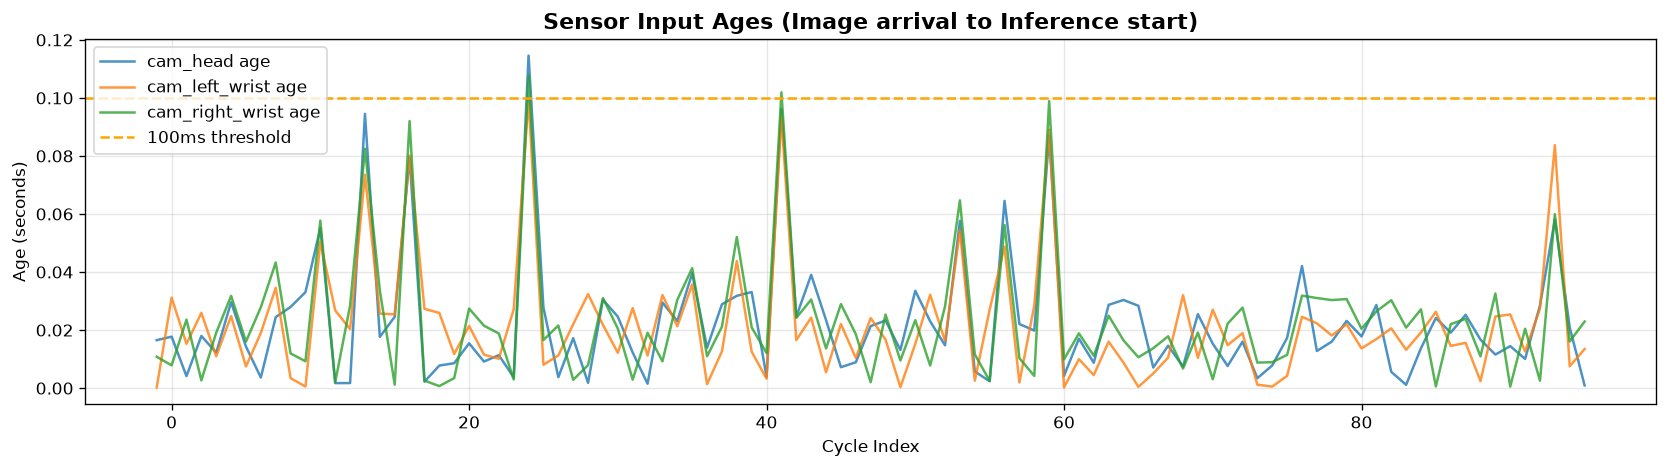

In [3]:
head_cam_ages = [d.get('input_ages', {}).get('camera:cam_head', 0) for d in cycles_data]
left_wrist_ages = [d.get('input_ages', {}).get('camera:cam_left_wrist', 0) for d in cycles_data]
right_wrist_ages = [d.get('input_ages', {}).get('camera:cam_right_wrist', 0) for d in cycles_data]

plt.figure(figsize=(14, 4), dpi=120)
plt.plot(cycles, head_cam_ages, label='cam_head age', alpha=0.8)
plt.plot(cycles, left_wrist_ages, label='cam_left_wrist age', alpha=0.8)
plt.plot(cycles, right_wrist_ages, label='cam_right_wrist age', alpha=0.8)
plt.axhline(0.1, color='orange', linestyle='--', label='100ms threshold')
plt.title("Sensor Input Ages (Image arrival to Inference start)", fontsize=13, fontweight='bold')
plt.xlabel("Cycle Index")
plt.ylabel("Age (seconds)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Trích xuất Quỹ đạo từ `events.jsonl`
Mỗi khi gửi lệnh xuống robot, `events.jsonl` ghi nhận `policy_command`:
- `raw_action`: Vector 16D mô hình dự đoán.
- `limited_command`: Vector 16D sau bộ kẹp an toàn (giới hạn 0.15 rad/step).
- `measured_state`: Vector 16D góc khớp thực tế đọc từ robot.

In [4]:
policy_commands = []
with open(SESSION_DIR / 'events.jsonl') as f:
    for line in f:
        ev = json.loads(line)
        if ev.get('kind') == 'policy_command':
            policy_commands.append(ev)

print(f"Đã đọc được {len(policy_commands)} policy_command events.")

if len(policy_commands) > 0:
    time_stamps = [ev['monotonic'] - policy_commands[0]['monotonic'] for ev in policy_commands]
    raw_actions = np.array([ev['raw_action'] for ev in policy_commands])
    limited_cmds = np.array([ev['limited_command'] for ev in policy_commands])
    measured_states = np.array([ev['measured_state'] for ev in policy_commands])
    tracking_max = [ev['tracking']['maximum'] for ev in policy_commands]
    tracking_worst = [ev['tracking']['worst_joint'] for ev in policy_commands]

Đã đọc được 50 policy_command events.


## 4. Biểu đồ Sai số bám quỹ đạo (Tracking Error)
Đánh giá độ lệch giữa lệnh gửi đi và vị trí thực tế của robot:

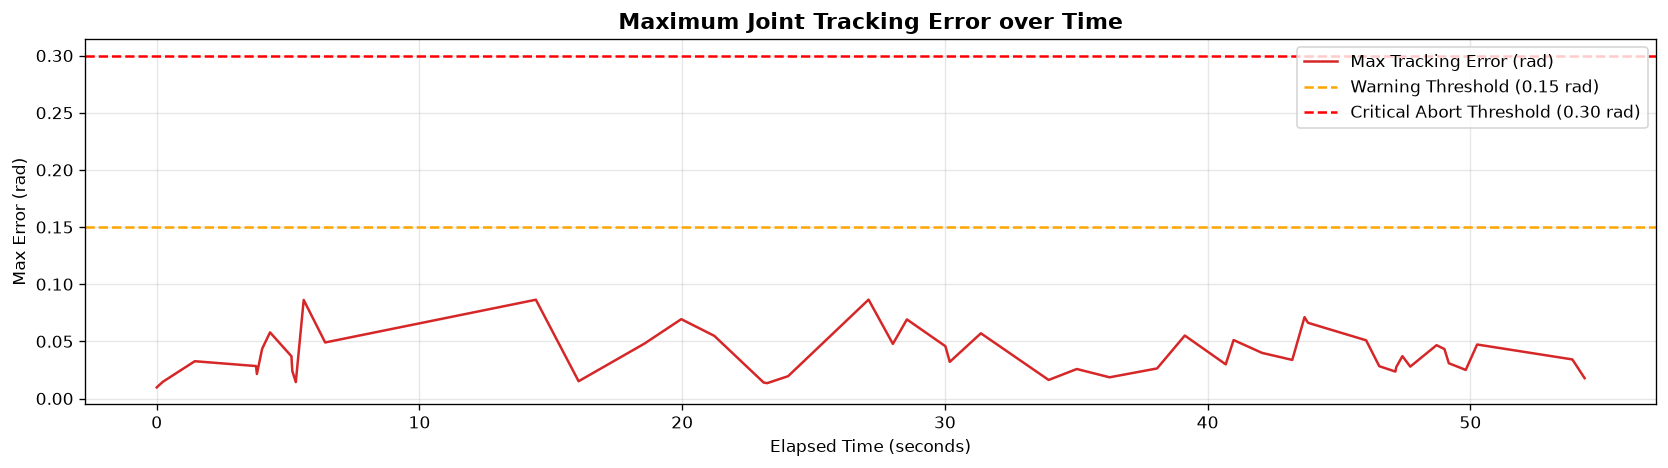

In [5]:
if len(policy_commands) > 0:
    plt.figure(figsize=(14, 4), dpi=120)
    plt.plot(time_stamps, tracking_max, color='#d62728', linewidth=1.5, label='Max Tracking Error (rad)')
    plt.axhline(0.15, color='orange', linestyle='--', label='Warning Threshold (0.15 rad)')
    plt.axhline(0.30, color='red', linestyle='--', label='Critical Abort Threshold (0.30 rad)')
    plt.title("Maximum Joint Tracking Error over Time", fontsize=13, fontweight='bold')
    plt.xlabel("Elapsed Time (seconds)")
    plt.ylabel("Max Error (rad)")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 5. So sánh Chi tiết Quỹ đạo từng Khớp (Joint Comparison)
Vẽ đồ thị so sánh giữa góc khớp thực tế (`measured`), góc mô hình muốn đi (`raw_action`), và góc sau lọc an toàn (`limited_command`) cho 7 khớp tay trái và 7 khớp tay phải:

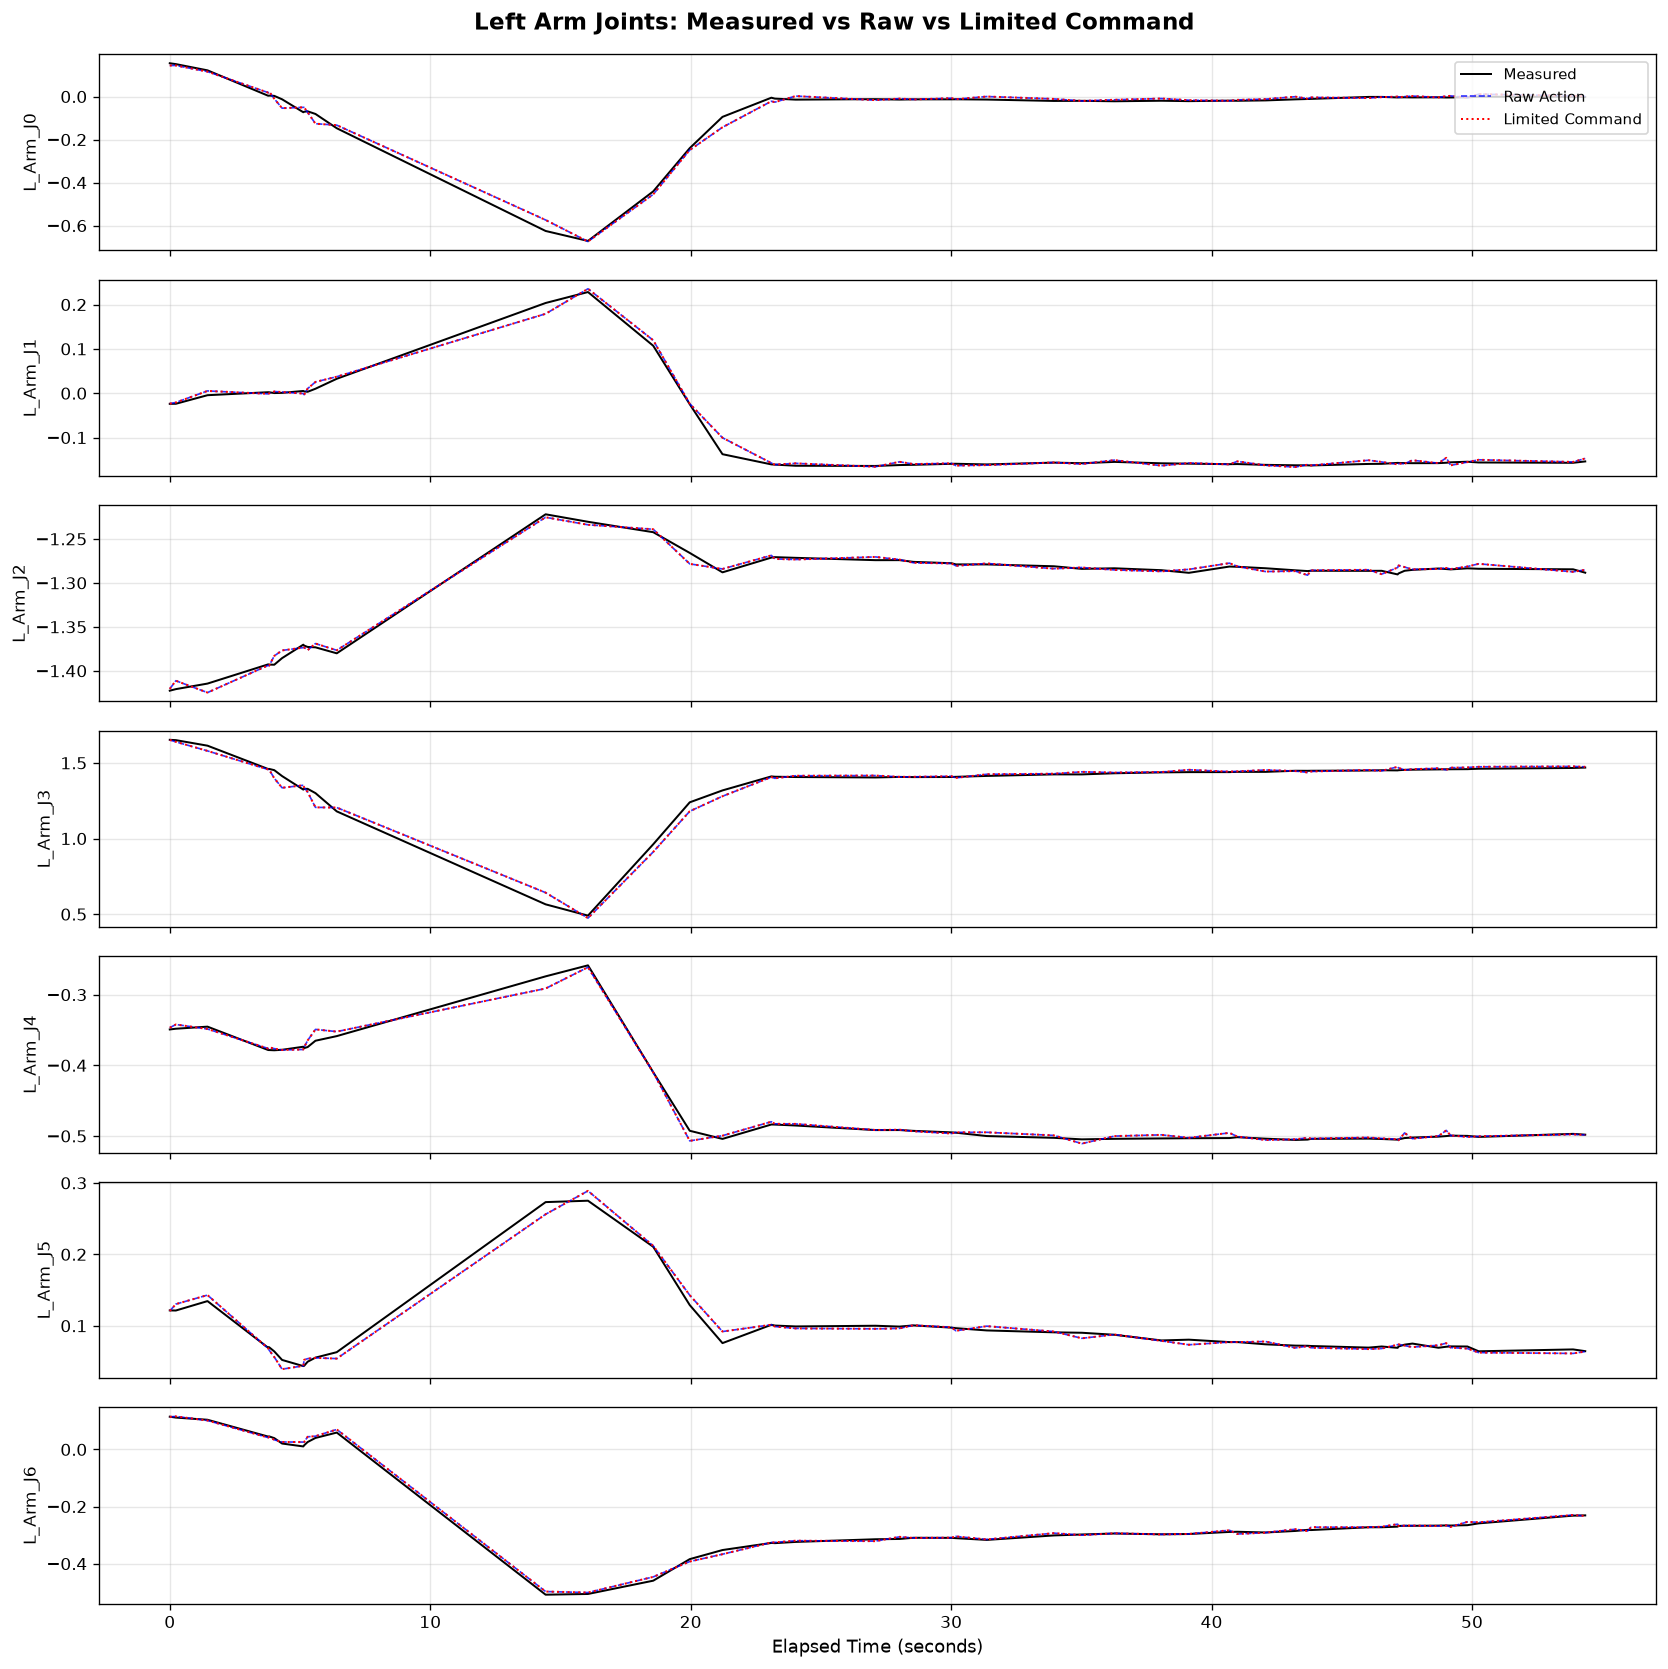

In [6]:
if len(policy_commands) > 0:
    # Vẽ 7 khớp tay trái (Left Arm J0..J6)
    fig, axes = plt.subplots(7, 1, figsize=(14, 14), sharex=True, dpi=120)
    fig.suptitle("Left Arm Joints: Measured vs Raw vs Limited Command", fontsize=14, fontweight='bold', y=0.99)
    for j in range(7):
        axes[j].plot(time_stamps, measured_states[:, j], 'k-', label='Measured', linewidth=1.2)
        axes[j].plot(time_stamps, raw_actions[:, j], 'b--', label='Raw Action', linewidth=1.0, alpha=0.8)
        axes[j].plot(time_stamps, limited_cmds[:, j], 'r:', label='Limited Command', linewidth=1.2)
        axes[j].set_ylabel(JOINT_NAMES[j], fontsize=10)
        axes[j].grid(True, alpha=0.3)
        if j == 0:
            axes[j].legend(loc='upper right', fontsize=9)
    axes[-1].set_xlabel("Elapsed Time (seconds)", fontsize=11)
    plt.tight_layout()
    plt.show()

## 6. Hành vi của Hai Kẹp Gắp (Left Gripper & Right Gripper)
Kiểm tra quỹ đạo đóng/mở của 2 kẹp (thang đo 0 đến 100):

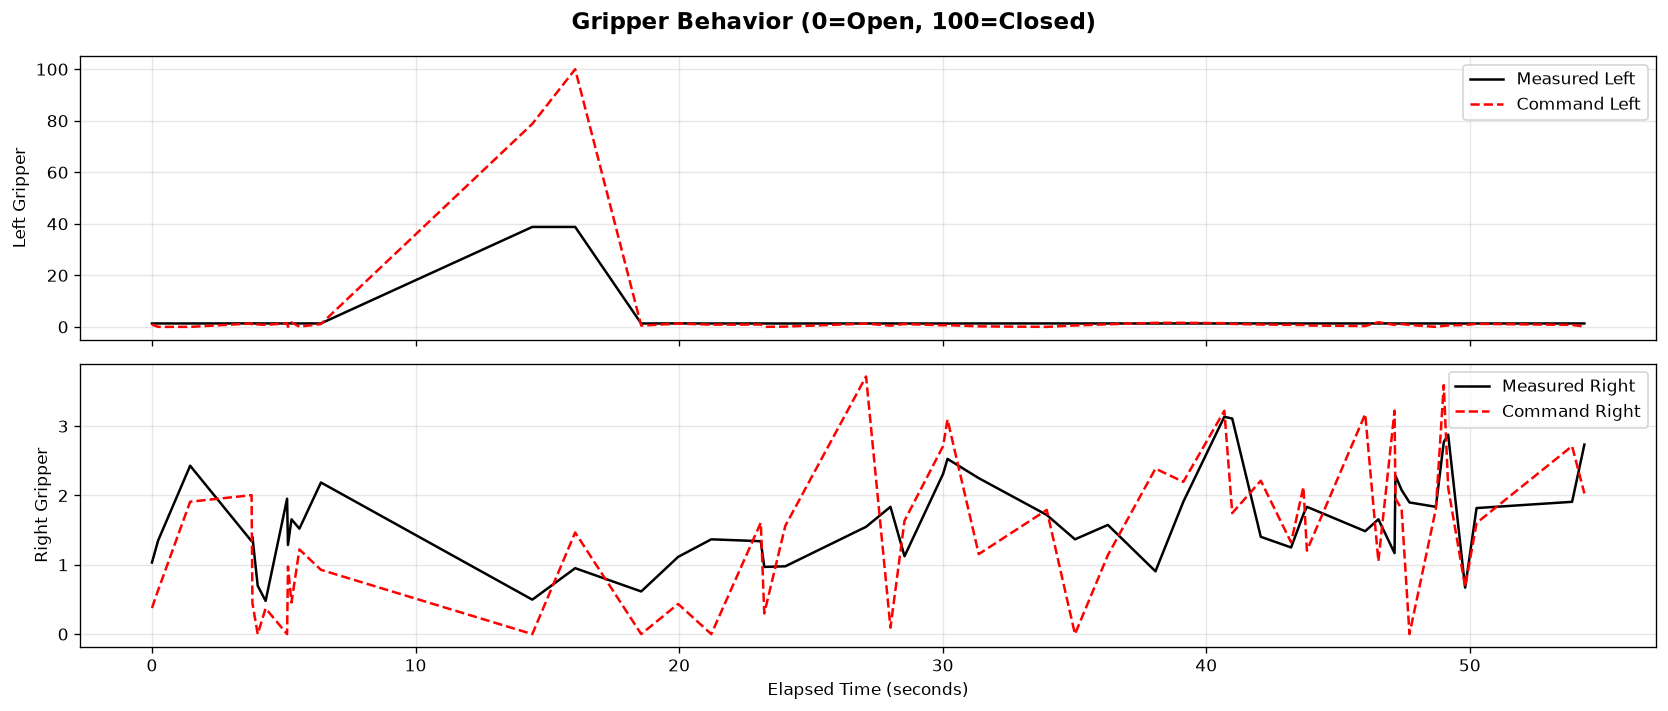

In [7]:
if len(policy_commands) > 0:
    fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True, dpi=120)
    fig.suptitle("Gripper Behavior (0=Open, 100=Closed)", fontsize=14, fontweight='bold')
    
    # Left Gripper (joint 14)
    axes[0].plot(time_stamps, measured_states[:, 14], 'k-', label='Measured Left')
    axes[0].plot(time_stamps, limited_cmds[:, 14], 'r--', label='Command Left')
    axes[0].set_ylabel("Left Gripper")
    axes[0].grid(True, alpha=0.3)
    axes[0].legend()
    
    # Right Gripper (joint 15)
    axes[1].plot(time_stamps, measured_states[:, 15], 'k-', label='Measured Right')
    axes[1].plot(time_stamps, limited_cmds[:, 15], 'r--', label='Command Right')
    axes[1].set_ylabel("Right Gripper")
    axes[1].set_xlabel("Elapsed Time (seconds)")
    axes[1].grid(True, alpha=0.3)
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()